# Supplementary Fig. 5: Model fits on the first trials of the blocks

[AI generated summary] The inferential RL (with stickiness) and foraging models are fitted to the choices of each monkey using all trials (left, the fits of Fig. 2b), only the first 10 trials of each block (middle) or only the first 15 trials of each block (right). The bars show the likelihood per trial (LPT) of the best fit, computed on the fitted trials (top: monkey KA, bottom: monkey PO). One figure per set of fitted trials.

**How to run:** run all cells (a few seconds). Figures are saved in `figs/`. The titles and the legend of the paper figure were added when the figure was assembled.

**Results:** precomputed results are provided in `results/behav_modeling/fitting, results/behav_modeling/fitting_first10 and results/behav_modeling/fitting_first15` (see the README). To recompute them, run in this folder: `python run_model_fitting.py` (all trials; Fig. 2b, ~18 h), `python run_model_fitting_first_trials.py 10` and `python run_model_fitting_first_trials.py 15` (~4 h each).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from popy.config import COLORS
from helpers import load_fitting_results  # load_res() of the original notebook (reads results/behav_modeling/<folder>)

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_res(res_all, paper_format=False, size=(4, 4)):
    # Set font size and figure size
    if paper_format:
        plt.rcParams.update({"font.size": 8})
        w, h = size
    else:
        plt.rcParams.update({"font.size": 8})
        w, h = ((12 / 5) / 3) * (len(res_all) / 2), 5 / 1

    # Define the modes and figure
    modes = ["LPT_best"]
    fig, axes = plt.subplots(
        2, 1, figsize=(w / 2.54, h / 2.54), gridspec_kw={"hspace": 0.3}
    )

    # Get unique values
    models = res_all.loc[res_all["monkey"] != "yu_DCZ", "Model"].unique()
    monkeys = res_all.loc[res_all["monkey"] != "yu_DCZ", "monkey"].unique()

    # Iterate over the modes and plot
    for mode_idx, mode in enumerate(modes):
        # Set up positions
        x = np.arange(len(models))
        width = 0.65  # Width of bars

        for i, monkey in enumerate(monkeys):
            ax = axes[i]  # Use separate subplot for each monkey

            data = res_all.loc[
                (res_all["monkey"] == monkey) & (res_all["monkey"] != "yu_DCZ")
            ]
            values = [
                (
                    data.loc[data["Model"] == model, mode].iloc[0]
                    if len(data.loc[data["Model"] == model]) > 0
                    else 0
                )
                for model in models
            ]

            # Create bars with model-based coloring
            for j, (model, value) in enumerate(zip(models, values)):
                hatch = None
                if model.split()[0] == "Standard":
                    # replace  what comes after with RL
                    color = COLORS["Standard RL"]
                    if (
                        not model == "Standard RL - stickiness" and not paper_format
                    ) or (paper_format and not model == "Standard RL"):
                        hatch = "///"  # Dashed filling pattern
                elif model.split()[0] == "Inferential":
                    color = COLORS["Inferential RL"]
                    if (
                        not model == "Inferential RL - stickiness" and not paper_format
                    ) or (paper_format and not model == "Inferential RL"):
                        hatch = "///"  # Dashed filling pattern
                elif model.split()[0] == "Foraging":
                    color = COLORS["Foraging"]
                    if not len(model.split(" ")) == 1:
                        hatch = "///"  # Dashed filling pattern
                else:
                    color = COLORS.get(model, "grey")
                    hatch = None
                alpha = 0.8

                bar = ax.bar(
                    x[j],
                    value,
                    width,
                    color=color,
                    hatch=hatch,
                    edgecolor="black",
                    linewidth=0.5,
                    alpha=alpha,
                )

                # Set hatch color to grey for RL-s models
                if model.split()[-1] == "RL-s":
                    import matplotlib as mpl

                    mpl.rcParams["hatch.color"] = "grey"

            for model, value in zip(models, values):
                print(f"{mode}: {monkey} {model}: {value:.2f}")

            # add monkey name (capitalized) as title, y axis a bit lower
            ax.set_title(monkey.upper(), fontsize=10, y=0.85)

            # Configure axes
            ax.set_ylim(0.3, 0.85)
            ax.set_yticks(np.arange(0.3, 0.9, 0.2))
            ax.set_ylabel("LPT", fontsize=8)

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

            ax.grid(axis="y", linestyle="dotted", alpha=0.5, zorder=0)

            # Only add x-axis labels to bottom plot
            if i == len(monkeys) - 1:  # Bottom plot
                ax.set_xticks(x)
                if paper_format:
                    ax.set_xticklabels(models, rotation=45, horizontalalignment="right")
                else:
                    ax.set_xticklabels(
                        models, rotation=-90, horizontalalignment="center"
                    )
            else:  # Top plot
                ax.set_xticks(x)
                ax.set_xticklabels([])  # Remove x-axis labels from top plot

    return fig, axes

---
# Load results

In [4]:
models = {"Inferential RL - stickiness": "Inferential RL", "Foraging": "Foraging"}

# result folders in results/behav_modeling: fit on all trials (Fig. 2b), on the first 10 and on the first 15 trials of each block
flocs = {
    "full": "fitting",
    "first10": "fitting_first10",
    "first15": "fitting_first15",
}

---
# Supplementary Fig. 5

Loading results from: fitting
LPT_best: ka Inferential RL: 0.75
LPT_best: ka Foraging: 0.79
LPT_best: po Inferential RL: 0.56
LPT_best: po Foraging: 0.60
Loading results from: fitting_first10
LPT_best: ka Inferential RL: 0.64
LPT_best: ka Foraging: 0.68
LPT_best: po Inferential RL: 0.49
LPT_best: po Foraging: 0.54
Loading results from: fitting_first15
LPT_best: ka Inferential RL: 0.68
LPT_best: ka Foraging: 0.72
LPT_best: po Inferential RL: 0.52
LPT_best: po Foraging: 0.56


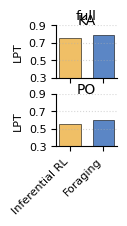

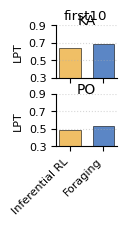

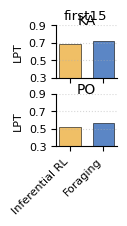

In [5]:
# show LPT 
for title, floc_base in flocs.items():
    print(f"Loading results from: {floc_base}")
    res_all = load_fitting_results(folder=floc_base)
    res_all = res_all[res_all['Model'].isin(models.keys())].copy()
    # revesre sort
    res_all = res_all.sort_values("Model", ascending=False)
    # rename models from key to values
    res_all["Model"] = res_all["Model"].replace(models)
    
    fig, ax = plot_res(res_all, paper_format=True, size=(2, 4))
    fig.suptitle(title)

    # save figure as svg 600 dpi
    fig.savefig(
        os.path.join(FIGS_PATH, f"figS5_lpt_{title}.svg"),
        dpi=600,
    )

In [6]:
# Export source data (Supplementary Figure 5)
from popy.source_data import export_source_data

# bar heights: LPT of the best fit (LPT_best) of the two models, for each set of fitted trials and monkey, as selected in the loop above
subsets = {"full": "All trials", "first10": "First 10 trials of each block", "first15": "First 15 trials of each block"}
rows = []
for title, floc_base in flocs.items():
    res_s5 = load_fitting_results(folder=floc_base)
    for monkey in ['ka', 'po']:
        for model, label in models.items():
            value = res_s5.loc[(res_s5['monkey'] == monkey) & (res_s5['Model'] == model), 'LPT_best'].iloc[0]
            rows.append({'Fitted trials': subsets[title], 'Monkey': monkey.upper(), 'Model': label, 'LPT': value})
export_source_data('Supplementary Figure 5', pd.DataFrame(rows),
                   'Likelihood per trial (LPT, geometric mean of the probability given by the model to the animal\'s choice) of the inferential RL '
                   '(with stickiness) and foraging models, fitted (maximum likelihood, no cross-validation) to all trials, to the first 10 or to the '
                   'first 15 trials of each block of each monkey; the LPT is computed on the fitted trials. No error bars.')

Supplementary Figure 5: source data saved (12 rows)
